# Gate 5B: MAttr interaction and component diagnostics

Uses frozen Gate 2 N128 rankings at 5,000 updates, the official MIB IOI dataset and corrected edge-patching implementation. No retraining or new masking algorithm. All run switches default to false; ordinary execution analyzes saved results.

In [1]:
from pathlib import Path
import json, os, subprocess, re
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/mattr_interactions').is_dir())
CAMPAIGN_REL = 'results/mattr_interactions/20261022_gate5b'
OUT = ROOT / CAMPAIGN_REL
RUN_TESTS = False
PREPARE = False
RUN_CAMPAIGN = False
REGENERATE_REPORT = False
print(OUT)


H:\GenAI Research\sketch_prune\results\mattr_interactions\20261022_gate5b


## Explicit execution controls

The pinned existing WSL environment runs official CUDA interventions. Preparation freezes candidates, pairs, decision criteria and source hashes before effects. Confirmation selection is frozen separately after train-only screening and before loading confirmation prompts. A completed campaign reuses artifacts; failed attempts remain preserved for inspection.

In [2]:
def run(*args):
    script = ROOT / 'src/mattr_interactions/run_wsl.sh'
    if os.name == 'nt':
        converted = '/mnt/' + script.drive[0].lower() + str(script)[2:].replace('\\', '/')
        command = ['wsl', '-d', 'Ubuntu', '--', 'bash', converted, *args]
    else:
        command = ['bash', str(script), *args]
    subprocess.run(command, cwd=ROOT, check=True)
if RUN_TESTS: run('tests')
if PREPARE: run('--out', CAMPAIGN_REL, '--prepare-only')
if RUN_CAMPAIGN: run('--out', CAMPAIGN_REL)
if REGENERATE_REPORT:
    run('--out', CAMPAIGN_REL, '--report-only')
    run('audit', '--out', CAMPAIGN_REL)


## Frozen selection and semantics

Official signed top-n circuits are connectivity-pruned once. Each subsequent toggle must survive official cleanup without changing additional edges. This excludes cleanup-confounded and disconnected additions; it cannot discover circuits requiring several connecting edges outside this candidate set. Donor-only caching copies unmodified corrupted sources; all patched sources are recomputed live.

In [3]:
protocol = json.loads((OUT / 'gate5b_protocol.json').read_text())
print('Protocol SHA-256:', (OUT / 'gate5b_protocol.sha256').read_text().strip())
display(protocol['criteria'])
display(pd.read_csv(OUT / 'topology_selection_audit.csv'))
display(pd.read_csv(OUT / 'selected_candidates.csv').head(12))
display(pd.read_csv(OUT / 'selected_pairs.csv').groupby(['fraction', 'direction', 'category', 'control']).size().rename('pairs').reset_index())


Protocol SHA-256: 2ed5dd02a7b58377b532e3753abf088034a68c999d17766953bc2c6d60ea1519


{'substantial_absolute_margin': 0.1,
 'substantial_relative_interaction': 0.2,
 'reproducible_selected_fraction_min': 0.5,
 'option_A_confirmed_pairs_min': 4,
 'option_A_useful_additions_min': 2,
 'useful_joint_margin_gain_min': 0.1,
 'useful_addition': 'positive held-out joint effect >=.1, interaction CI excludes0, signed interaction agrees with train, joint > max(single_i,single_j), accuracy gain positive and bootstrap95 lower>=0',
 'option_B_component_spearman_gain_min': 0.1,
 'option_B_null_percentile': 0.95,
 'option_B_groupings_min': 2,
 'option_B_interaction_concentration_ratio_min': 1.5,
 'option_B_concentration': 'same receiver/component mean absolute confirmed interaction >=1.5 times type/layer matched random controls, with prompt-bootstrap CI for the difference excluding0; insufficient controls means inconclusive, not success',
 'uncertainty': 'Shared prompt bootstrap indices across pairs; per-pair95% and familywise Bonferroni intervals. No bootstrap over correlated pair/thr

,fraction,direction,candidates,valid_pairs,joint_cleanup_rejections,selected_pairs,safe_singles_total,base_edges,requested_edges
0,0.01,deletion,24,276,0,49,7033,317,324
1,0.01,addition,24,276,0,47,7033,317,324
2,0.02,deletion,24,276,0,47,10800,646,649
3,0.02,addition,24,276,0,48,10800,646,649


,mattr_index,edge,eap_row,eap_column,parent,child,qkv,destination_hook,parent_type,child_type,source_layer,destination_layer,edge_type,rank,eap_rank,disagreement,fraction,direction,stratum
0,5717,m0->a10.h7<v>,13,401,m0,a10.h7,v,blocks.10.hook_v_input,MLP,attention,0,10,MLP->attention,1,50.0,49.0,0.01,deletion,high
1,17334,a3.h8->m3,48,147,a3.h8,m3,NaN,blocks.3.hook_mlp_in,attention,MLP,3,3,attention->MLP,2,30576.0,30574.0,0.01,deletion,high
2,24258,a5.h9->a6.h2<v>,75,248,a5.h9,a6.h2,v,blocks.6.hook_v_input,attention,attention,5,6,attention->attention,3,30591.0,30588.0,0.01,deletion,high
3,24929,m5->a6.h2<v>,78,248,m5,a6.h2,v,blocks.6.hook_v_input,MLP,attention,5,6,MLP->attention,10,2625.0,2615.0,0.01,deletion,high
4,30294,a8.h6->m11,111,443,a8.h6,m11,NaN,blocks.11.hook_mlp_in,attention,MLP,8,11,attention->MLP,12,631.0,619.0,0.01,deletion,high
5,22442,a5.h1->a6.h2<q>,67,224,a5.h1,a6.h2,q,blocks.6.hook_q_input,attention,attention,5,6,attention->attention,14,24496.0,24482.0,0.01,deletion,high
6,21956,m4->a5.h1<q>,65,186,m4,a5.h1,q,blocks.5.hook_q_input,MLP,attention,4,5,MLP->attention,15,31826.0,31811.0,0.01,deletion,high
7,28754,a7.h7->m11,99,443,a7.h7,m11,NaN,blocks.11.hook_mlp_in,attention,MLP,7,11,attention->MLP,17,17015.0,16998.0,0.01,deletion,high
8,31916,m9->a10.h7<v>,130,401,m9,a10.h7,v,blocks.10.hook_v_input,MLP,attention,9,10,MLP->attention,324,31839.0,31515.0,0.01,deletion,boundary
9,32432,m10->a11.h4<q>,143,411,m10,a11.h4,q,blocks.11.hook_q_input,MLP,attention,10,11,MLP->attention,323,3473.0,3150.0,0.01,deletion,boundary


,fraction,direction,category,control,pairs
0,0.01,addition,different_components,False,15
1,0.01,addition,different_components,True,13
2,0.01,addition,same_component,False,15
3,0.01,addition,same_component,True,2
4,0.01,addition,same_receiver,False,2
5,0.01,deletion,different_components,False,15
6,0.01,deletion,different_components,True,15
7,0.01,deletion,same_component,False,15
8,0.01,deletion,same_receiver,False,4
9,0.02,addition,different_components,False,15


## Correctness and compute

The pinned corrected live loss closure is used only as an oracle; the official trainer is intercepted and never called. Independent official MIB evaluation, dependent multi-edge paths, cache equivalence, repeatability and singleton batching must pass before screening. Forward counts represent actual model calls; cache lookups are tracked separately.

In [4]:
display(json.loads((OUT / 'correctness_passed.json').read_text()))
display(pd.read_csv(OUT / 'live_patching_audit.csv'))
display(pd.read_csv(OUT / 'donor_cache_audit.csv'))
display(pd.read_csv(OUT / 'compute_accounting.csv'))
display(json.loads((OUT / 'process_summary.json').read_text()))


{'passed': True,
 'masks': 9,
 'live_patcher': 'pinned corrected eval_mib_edge.py',
 'official_oracle': 'eap.evaluate.evaluate_graph, normal prune enabled',
 'dependent_multi_edge_checked': True,
 'batch_single_max_error': 1.239776611328125e-05,
 'training_updates': 0,
 'model_backwards': 0}

,mask,live_vs_official_max_error,examples,passed
0,full,0.000006,2,True
1,empty,0.000012,2,True
2,base_0.01,0.000031,2,True
3,0.01_deletion_joint,0.000028,2,True
4,0.01_addition_joint,0.000032,2,True
5,base_0.02,0.000061,2,True
6,0.02_deletion_joint,0.000031,2,True
7,0.02_addition_joint,0.000046,2,True
8,dependent_two_edge_path,0.000012,2,True


,mask,metric,donor_cache_max_error,repeat_error,passed
0,full,margin,0.0,0.0,True
1,full,accuracy,0.0,0.0,True
2,empty,margin,0.0,0.0,True
3,empty,accuracy,0.0,0.0,True
4,base_0.01,margin,0.0,0.0,True
5,base_0.01,accuracy,0.0,0.0,True
6,0.01_deletion_joint,margin,0.0,0.0,True
7,0.01_deletion_joint,accuracy,0.0,0.0,True
8,0.01_addition_joint,margin,0.0,0.0,True
9,0.01_addition_joint,accuracy,0.0,0.0,True


,stage,success,seconds,forward_batches,example_forwards,backward_calls,optimizer_updates,peak_allocated_mib,peak_reserved_mib,sampled_peak_cpu_rss_mib
0,offline_ranking_stability,True,4.526161,0,0,0,0,0.000000,0.0,1088.726562
1,model_loading,True,15.563643,0,0,0,0,635.514160,690.0,2975.656250
2,training_cohort_loading,True,0.931434,0,0,0,0,635.514160,690.0,1189.492188
3,correctness_checks,True,7.916262,80,136,0,0,842.172363,922.0,1779.183594
4,training_screen,True,163.547272,2296,9184,0,0,951.242188,1474.0,2117.507812
5,confirmation_cohort_loading,True,4.094093,0,0,0,0,675.541504,1474.0,2127.792969
6,heldout_confirmation,True,74.366858,1072,4288,0,0,965.316895,1690.0,2746.289062


{'success': True,
 'seconds': 286.783557991,
 'counts': {'forward_batches': 3448,
  'example_forwards': 13608,
  'backward_calls': 0,
  'optimizer_updates': 0},
 'unique_evaluations_this_run': 373,
 'exact_cache_hits': 528,
 'donor_cache_hits': 3338,
 'donor_cache_misses': 27,
 'donor_cache_cpu_bytes': 973289472}

## Training-screen and held-out results

Screening uses 32 exact Gate 2 discovery prompts. Confirmation uses 64 official validation prompts disjoint from previous small Gate 2–5A development cohorts and all discovery pools. Gate 1 historically evaluated the complete validation split: freshness here is relative to the development cohorts, not all previous research. Selection uses training outcomes only. Shared prompt bootstrap draws preserve dependence between pair effects; familywise intervals are also saved.

In [5]:
display(pd.read_csv(OUT / 'screen_summary.csv'))
display(pd.read_csv(OUT / 'confirmation_summary.csv'))
display(pd.read_csv(OUT / 'heldout_consistency.csv')[['pair_id', 'selection_role', 'interaction_train', 'interaction_validation', 'interaction_lo', 'interaction_hi', 'joint_validation', 'accuracy_joint', 'useful_addition']])
display(json.loads((OUT / 'confirmation_selection_frozen.json').read_text()))
display(pd.read_csv(OUT / 'confirmation_control_matches.csv'))
display(pd.read_csv(OUT / 'confirmation_per_example.csv').head(12))


,fraction,direction,pairs,mean_abs_interaction,median_abs_interaction,substantial_fraction,additive_sign_disagreements
0,0.01,addition,47,0.000949,0.000169,0.000000,0
1,0.01,deletion,49,0.084305,0.004562,0.061224,0
2,0.02,addition,48,0.002480,0.000345,0.000000,0
3,0.02,deletion,47,0.154252,0.033484,0.021277,0


,fraction,direction,pairs,sign_consistency,reproduced_substantial,familywise_CI_nonzero,useful_additions,joint_accuracy_gain
0,0.01,addition,4,1.00,0,3,0,0.000000
1,0.01,deletion,4,1.00,1,4,0,-0.007812
2,0.02,addition,4,1.00,0,2,0,0.000000
3,0.02,deletion,4,0.75,1,3,0,0.000000


,pair_id,selection_role,interaction_train,interaction_validation,interaction_lo,interaction_hi,joint_validation,accuracy_joint,useful_addition
0,0.01_deletion_22442_24929,primary,3.770668e-01,0.122474,0.081239,0.168412,-0.619364,0.000000,False
1,0.01_deletion_18562_21956,primary,7.634520e-01,0.314866,0.232343,0.407396,-3.987841,-0.015625,False
2,0.01_deletion_21956_22442,primary,7.340936e-01,0.290448,0.204795,0.387293,-0.494224,0.000000,False
3,0.01_deletion_18562_30190,primary,2.310479e-01,0.239815,0.175567,0.308575,-5.260419,-0.015625,False
4,0.01_deletion_22442_29386,matched_control,-1.015724e-02,-0.001113,-0.006177,0.003288,-1.118577,0.000000,False
5,0.01_deletion_14997_22442,matched_control,1.154955e-01,0.046177,0.028824,0.065385,-1.748397,-0.015625,False
6,0.01_deletion_17334_21956,matched_control,1.372413e-01,0.023867,0.009093,0.041787,-0.885631,0.000000,False
7,0.01_addition_3496_22242,primary,9.509727e-03,0.005004,0.002736,0.007889,0.165731,0.000000,False
8,0.01_addition_26876_30108,primary,8.943334e-03,0.005435,-0.002065,0.011781,0.055867,0.000000,False
9,0.01_addition_1004_22242,primary,4.505694e-03,0.007036,0.003390,0.011576,0.261230,0.000000,False


{'primary_pair_ids': ['0.01_addition_3496_22242',
  '0.01_addition_26876_30108',
  '0.01_addition_1004_22242',
  '0.01_addition_1004_30972',
  '0.01_deletion_18562_21956',
  '0.01_deletion_21956_22442',
  '0.01_deletion_22442_24929',
  '0.01_deletion_18562_30190',
  '0.02_addition_30972_31884',
  '0.02_addition_23446_30972',
  '0.02_addition_24908_26098',
  '0.02_addition_29457_30972',
  '0.02_deletion_24258_24929',
  '0.02_deletion_4535_18562',
  '0.02_deletion_22442_24258',
  '0.02_deletion_17334_18562'],
 'pair_ids': ['0.01_deletion_22442_24929',
  '0.01_deletion_18562_21956',
  '0.01_deletion_21956_22442',
  '0.01_deletion_18562_30190',
  '0.01_deletion_22442_29386',
  '0.01_deletion_14997_22442',
  '0.01_deletion_17334_21956',
  '0.01_addition_3496_22242',
  '0.01_addition_26876_30108',
  '0.01_addition_1004_22242',
  '0.01_addition_1004_30972',
  '0.01_addition_30108_30972',
  '0.01_addition_3496_26876',
  '0.01_addition_25664_32269',
  '0.02_deletion_24258_24929',
  '0.02_deleti

,primary_pair,control_pair,type_layer_mismatch
0,0.01_deletion_22442_24929,0.01_deletion_22442_29386,2
1,0.01_deletion_18562_21956,0.01_deletion_17334_21956,2
2,0.01_deletion_21956_22442,0.01_deletion_14997_22442,2
3,0.01_deletion_18562_30190,0.01_deletion_14997_22442,4
4,0.01_addition_3496_22242,0.01_addition_3496_26876,2
5,0.01_addition_26876_30108,0.01_addition_25664_32269,3
6,0.01_addition_1004_22242,0.01_addition_3496_26876,3
7,0.01_addition_1004_30972,0.01_addition_30108_30972,2
8,0.02_deletion_24258_24929,0.02_deletion_23445_24929,1
9,0.02_deletion_17334_18562,0.02_deletion_15546_17085,2


,pair_id,example,single_i,single_j,joint,interaction,accuracy_joint,accuracy_i,accuracy_j
0,0.01_deletion_22442_24929,0,-0.057981,-0.039223,-0.092887,0.004316,0.0,0.0,0.0
1,0.01_deletion_22442_24929,1,-0.044088,-0.285633,-0.310345,0.019377,0.0,0.0,0.0
2,0.01_deletion_22442_24929,2,0.021460,-0.089222,-0.069963,-0.002201,0.0,0.0,0.0
3,0.01_deletion_22442_24929,3,-0.296640,-0.501753,-0.717373,0.081020,0.0,0.0,0.0
4,0.01_deletion_22442_24929,4,-0.007662,-0.050057,-0.056455,0.001265,0.0,0.0,0.0
5,0.01_deletion_22442_24929,5,0.074722,-0.763321,-0.715271,-0.026672,0.0,0.0,0.0
6,0.01_deletion_22442_24929,6,-0.024652,-0.186653,-0.207191,0.004115,0.0,0.0,0.0
7,0.01_deletion_22442_24929,7,-0.248632,-0.328733,-0.504088,0.073277,0.0,0.0,0.0
8,0.01_deletion_22442_24929,8,-0.007710,-0.548862,-0.553131,0.003441,0.0,0.0,0.0
9,0.01_deletion_22442_24929,9,-0.641577,-0.523428,-0.905132,0.259872,0.0,0.0,0.0


## Component structure and size controls

Source heads, destination heads, Q/K/V receivers, MLPs and layers are analyzed separately. Component importance uses normalized mean rank and eligibility-normalized retained fractions. Common edge-label permutations across seeds preserve edge-score covariance and component size, testing whether aggregation alone explains stability. The saved Gate 2 seeds vary both discovery subsets and optimizer randomness; these three rankings do not disentangle those sources.

In [6]:
display(pd.read_csv(OUT / 'stability_null_comparison.csv'))
display(pd.read_csv(OUT / 'ranking_stability.csv'))
display(pd.read_csv(OUT / 'edge_membership_stability.csv'))
display(pd.read_csv(OUT / 'component_statistics.csv').head(16))
display(pd.read_csv(OUT / 'historical_attribution_reference.csv'))
display(pd.read_csv(OUT / 'within_component_edge_stability.csv').head(12))
display(pd.read_csv(OUT / 'component_identity_explanation.csv').groupby('grouping').mean(numeric_only=True))
display(pd.read_csv(OUT / 'conditional_edge_effects.csv').head(12))
display(pd.read_csv(OUT / 'four_way_scores.csv').head(12))
display(json.loads((OUT / 'final_validation.json').read_text()))


,grouping,components,edge_mean_spearman,component_mean_spearman,component_gain,common_permutation_null_mean,common_permutation_null_95,above_null_95
0,source_head,144,0.368862,0.619903,0.251041,0.340105,0.446455,True
1,destination_head,144,0.368862,0.617442,0.248580,0.330549,0.455418,True
2,qkv_receiver,432,0.368862,0.546923,0.178060,0.318779,0.383858,True
3,source_MLP,12,0.368862,0.920746,0.551884,0.306492,0.673776,True
4,destination_MLP,12,0.368862,0.568765,0.199902,0.309650,0.635548,False
5,source_layer,12,0.368862,0.477855,0.108993,0.316550,0.632867,False
6,destination_layer,12,0.368862,0.923077,0.554215,0.333159,0.716084,True


,grouping,seed_a,seed_b,rank_spearman,top10pct_jaccard
0,edge,42,43,0.351566,0.373204
1,edge,42,44,0.364278,0.383731
2,edge,43,44,0.390743,0.408628
3,source_head,42,43,0.576429,0.363636
4,source_head,42,44,0.696704,0.363636
5,source_head,43,44,0.586577,0.500000
6,destination_head,42,43,0.638015,0.500000
7,destination_head,42,44,0.542669,0.428571
8,destination_head,43,44,0.671642,0.578947
9,qkv_receiver,42,43,0.537274,0.517241


,grouping,fraction,seed_a,seed_b,jaccard
0,edge,0.005,42,43,0.459893
1,edge,0.010,42,43,0.500000
2,edge,0.020,42,43,0.543373
3,edge,0.050,42,43,0.445291
4,edge,0.005,42,44,0.412935
5,edge,0.010,42,44,0.574257
6,edge,0.020,42,44,0.544258
7,edge,0.050,42,44,0.454463
8,edge,0.005,43,44,0.441748
9,edge,0.010,43,44,0.544578


,grouping,component,seed,fraction,eligible_edges,retained_edges,retained_fraction,enrichment,mean_rank_percentile,score_mean,score_std,score_min,score_max,rank_percentile_median,rank_percentile_std
0,source_head,a0.h0,42,0.005,409,0,0.000000,0.000000,0.494246,-0.861681,1.185091,-5.324776,2.784140,0.509264,0.202348
1,source_head,a0.h1,42,0.005,409,0,0.000000,0.000000,0.485582,-0.812813,3.287151,-9.394310,9.267200,0.479194,0.327728
2,source_head,a0.h10,42,0.005,409,0,0.000000,0.000000,0.478663,-0.881594,2.432309,-7.591458,9.459502,0.468021,0.285690
3,source_head,a0.h11,42,0.005,409,0,0.000000,0.000000,0.502728,-0.805499,1.162631,-6.065989,3.638105,0.505848,0.198838
4,source_head,a0.h2,42,0.005,409,0,0.000000,0.000000,0.485928,-0.900168,1.118550,-5.075562,3.290156,0.485996,0.197461
5,source_head,a0.h3,42,0.005,409,0,0.000000,0.000000,0.510235,-0.729205,2.471763,-8.974053,6.735785,0.505509,0.294925
6,source_head,a0.h4,42,0.005,409,0,0.000000,0.000000,0.529371,-0.685221,2.693869,-10.308633,6.723548,0.551493,0.308996
7,source_head,a0.h5,42,0.005,409,0,0.000000,0.000000,0.471633,-1.049651,2.687342,-9.952753,6.506673,0.469283,0.305583
8,source_head,a0.h6,42,0.005,409,0,0.000000,0.000000,0.502902,-0.839131,1.603103,-6.804785,4.393212,0.534780,0.239319
9,source_head,a0.h7,42,0.005,409,1,0.002445,0.611078,0.486931,-0.873663,2.169269,-7.206352,9.034601,0.495814,0.273594


,seed,reference,signed_rank_spearman,top1pct_raw_ranking_jaccard
0,42,saved official EAP-IG,0.081521,0.153025
1,43,saved official EAP-IG,0.081640,0.193370
2,44,saved official EAP-IG,0.074970,0.171790


,grouping,component,fraction,seed_a,seed_b,eligible_edges,retained_a,retained_b,intersection,union,within_component_edge_jaccard
0,source_head,a0.h0,0.01,42,43,409,0,0,0,0,NaN
1,source_head,a0.h1,0.01,42,43,409,9,8,6,11,0.545455
2,source_head,a0.h10,0.01,42,43,409,0,7,0,7,0.000000
3,source_head,a0.h11,0.01,42,43,409,0,0,0,0,NaN
4,source_head,a0.h2,0.01,42,43,409,0,0,0,0,NaN
5,source_head,a0.h3,0.01,42,43,409,0,0,0,0,NaN
6,source_head,a0.h4,0.01,42,43,409,0,0,0,0,NaN
7,source_head,a0.h5,0.01,42,43,409,0,0,0,0,NaN
8,source_head,a0.h6,0.01,42,43,409,0,0,0,0,NaN
9,source_head,a0.h7,0.01,42,43,409,2,2,1,3,0.333333


,source_seed,target_seed,within_source_seed_eta_squared,cross_seed_component_only_R2,cross_seed_component_prediction_spearman,cross_seed_individual_edge_spearman_same_edges
grouping,,,,,,
destination_MLP,42.333333,43.666667,0.025179,0.008247,0.099699,0.639937
destination_head,42.333333,43.666667,0.010319,0.003379,0.059691,0.351978
destination_layer,42.333333,43.666667,0.004193,0.003717,0.052748,0.364886
qkv_receiver,42.333333,43.666667,0.028842,0.003986,0.084674,0.351978
source_MLP,42.333333,43.666667,0.041025,0.031789,0.198873,0.570508
source_head,42.333333,43.666667,0.017196,0.004421,0.074020,0.342407
source_layer,42.333333,43.666667,0.000884,-0.000161,0.009639,0.366671


,cohort,pair_id,fraction,direction,single_i,single_j,joint,conditional_i_given_j,conditional_j_given_i,i_effect_sign_changes,j_effect_sign_changes,joint_improves_margin,joint_accuracy_gain
0,screen,0.01_deletion_28754_30294,0.01,deletion,-0.323669,-0.885161,-1.213933,-0.328771,-0.890264,False,False,False,-0.03125
1,screen,0.01_deletion_5717_31916,0.01,deletion,-0.204176,0.000782,-0.197267,-0.198049,0.006908,False,False,False,-0.03125
2,screen,0.01_deletion_24258_24929,0.01,deletion,-0.522985,-0.767663,-1.177761,-0.410098,-0.654776,False,False,False,-0.03125
3,screen,0.01_deletion_26316_29386,0.01,deletion,-0.660721,-1.025612,-1.662319,-0.636707,-1.001597,False,False,False,0.00000
4,screen,0.01_deletion_26316_30294,0.01,deletion,-0.660721,-0.885161,-1.390709,-0.505548,-0.729988,False,False,False,-0.03125
5,screen,0.01_deletion_29373_29386,0.01,deletion,-0.015717,-1.025612,-1.040788,-0.015176,-1.025071,False,False,False,0.00000
6,screen,0.01_deletion_29386_30294,0.01,deletion,-1.025612,-0.885161,-1.795735,-0.910573,-0.770123,False,False,False,-0.03125
7,screen,0.01_deletion_22442_24929,0.01,deletion,-0.767097,-0.767663,-1.157693,-0.390030,-0.390596,False,False,False,-0.03125
8,screen,0.01_deletion_26396_32432,0.01,deletion,-0.016481,-0.210773,-0.227073,-0.016300,-0.210591,False,False,False,0.00000
9,screen,0.01_deletion_26316_30190,0.01,deletion,-0.660721,-2.560491,-3.149608,-0.589117,-2.488887,False,False,False,-0.03125


,cohort,pair_id,fraction,direction,F_base,F_i,F_j,F_ij,accuracy_base,accuracy_i,accuracy_j,accuracy_ij
0,screen,0.01_deletion_28754_30294,0.01,deletion,20.327927,20.004261,19.442766,19.113995,1.0,1.00000,0.96875,0.96875
1,screen,0.01_deletion_5717_31916,0.01,deletion,20.327927,20.123753,20.328712,20.130661,1.0,0.96875,1.00000,0.96875
2,screen,0.01_deletion_24258_24929,0.01,deletion,20.327927,19.804943,19.560265,19.150166,1.0,1.00000,0.96875,0.96875
3,screen,0.01_deletion_26316_29386,0.01,deletion,20.327927,19.667208,19.302319,18.665609,1.0,1.00000,1.00000,1.00000
4,screen,0.01_deletion_26316_30294,0.01,deletion,20.327927,19.667208,19.442766,18.937220,1.0,1.00000,0.96875,0.96875
5,screen,0.01_deletion_29373_29386,0.01,deletion,20.327927,20.312212,19.302319,19.287140,1.0,1.00000,1.00000,1.00000
6,screen,0.01_deletion_29386_30294,0.01,deletion,20.327927,19.302319,19.442766,18.532194,1.0,1.00000,0.96875,0.96875
7,screen,0.01_deletion_22442_24929,0.01,deletion,20.327927,19.560831,19.560265,19.170235,1.0,1.00000,0.96875,0.96875
8,screen,0.01_deletion_26396_32432,0.01,deletion,20.327927,20.311447,20.117157,20.100857,1.0,1.00000,1.00000,1.00000
9,screen,0.01_deletion_26316_30190,0.01,deletion,20.327927,19.667208,17.767437,17.178322,1.0,1.00000,0.96875,0.96875


{'passed': True,
 'protocol_sha256': '2ed5dd02a7b58377b532e3753abf088034a68c999d17766953bc2c6d60ea1519',
 'frozen_source_hashes': 8,
 'protected_historical_files_unchanged': 3550,
 'candidate_edges': 96,
 'screen_pairs': 191,
 'confirmation_pairs': 29,
 'four_way_cache_reconstructions': 220,
 'confirmation_prompts': 64,
 'prior_small_validation_manifests_checked': 61,
 'cpu_tests': 7,
 'counts': {'forward_batches': 3448,
  'example_forwards': 13608,
  'backward_calls': 0,
  'optimizer_updates': 0},
 'additional_model_forwards': 0,
 'audit_source_sha256': '3f842b2c0a2c23f822a594e9199d136995563520b5469c40b0d1c1368d418398',
 'seconds': 33.222367404999986}

## Figures and frozen decision

Large nonadditivity does not by itself identify useful missed circuits or establish an algorithmic improvement over MAttr’s joint soft-mask training. The report applies the preregistered diagnostic criteria and stops without implementing either proposed algorithm.

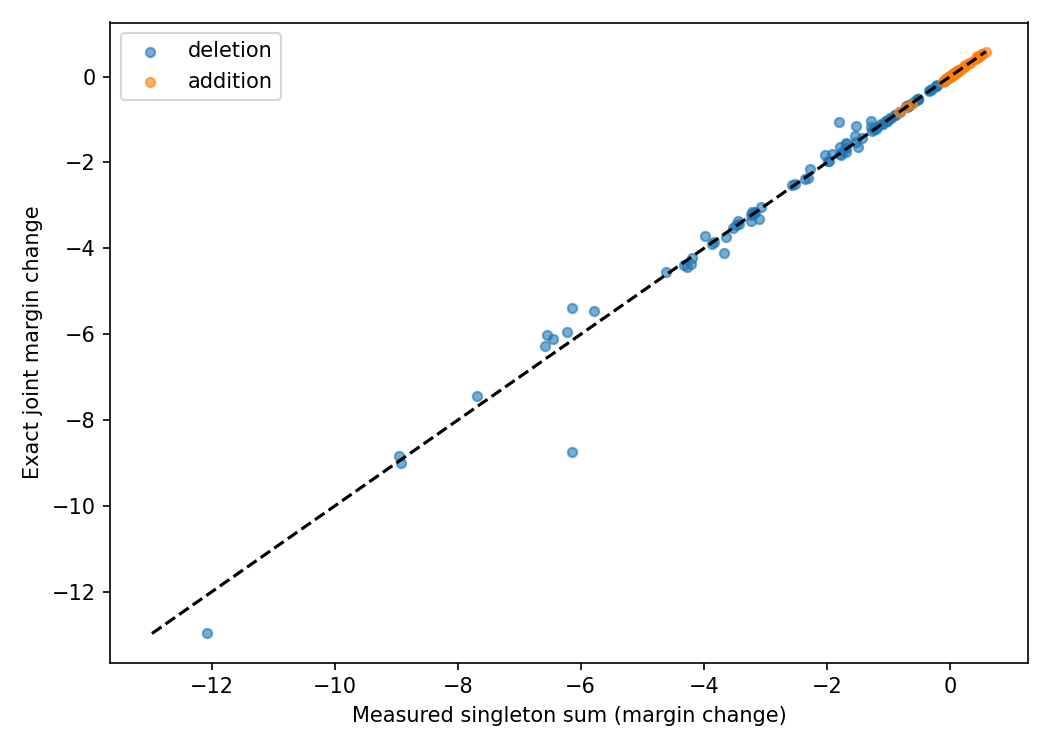

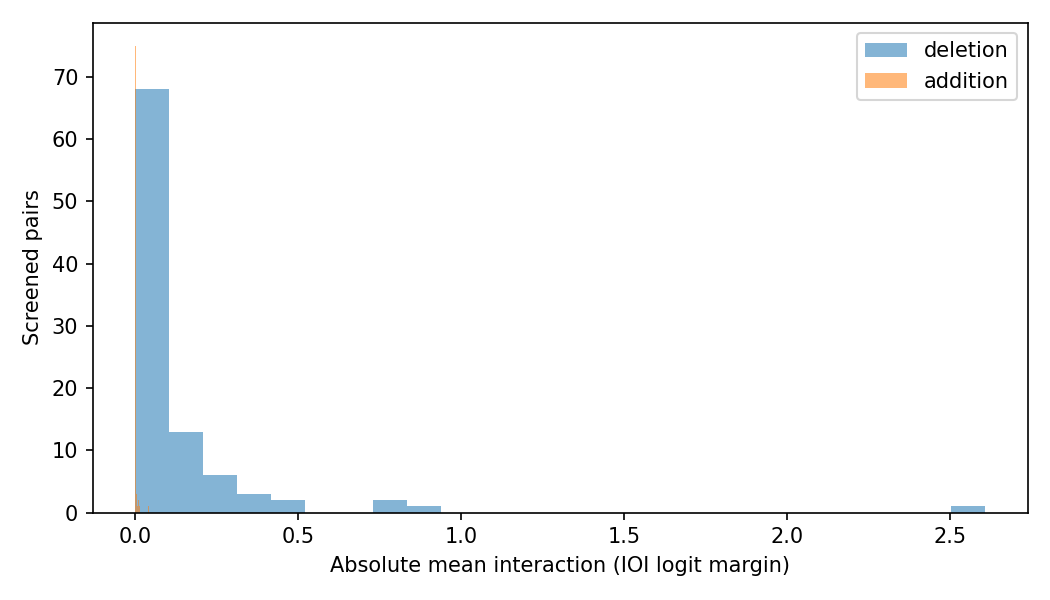

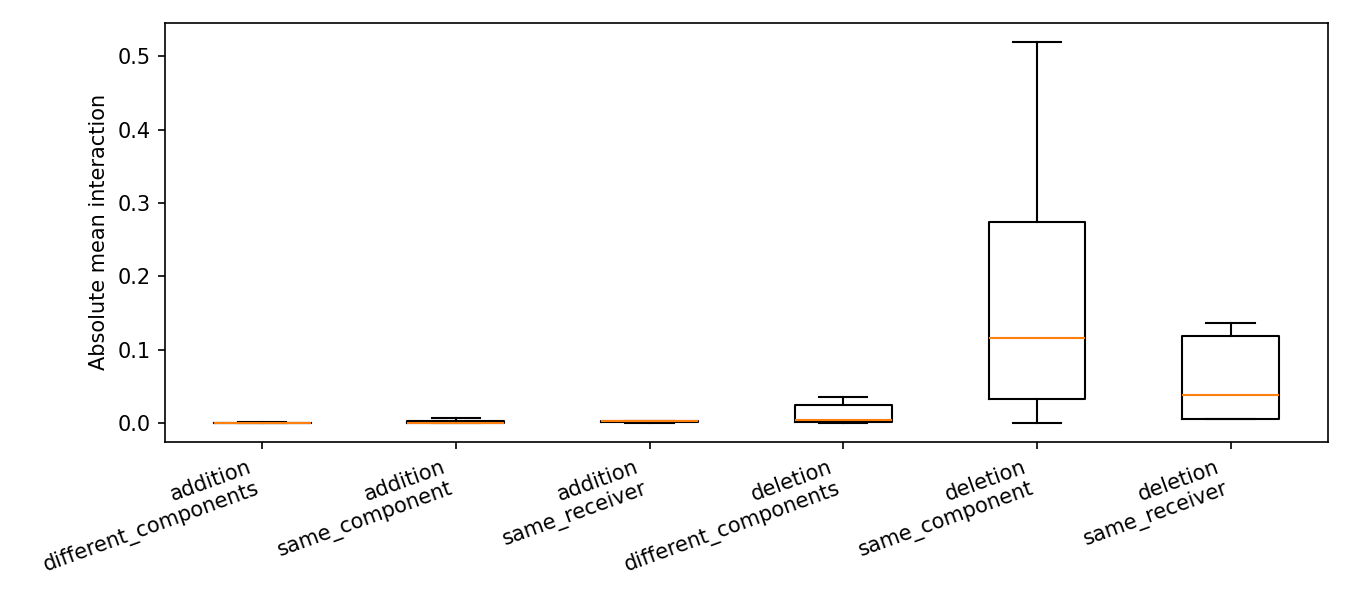

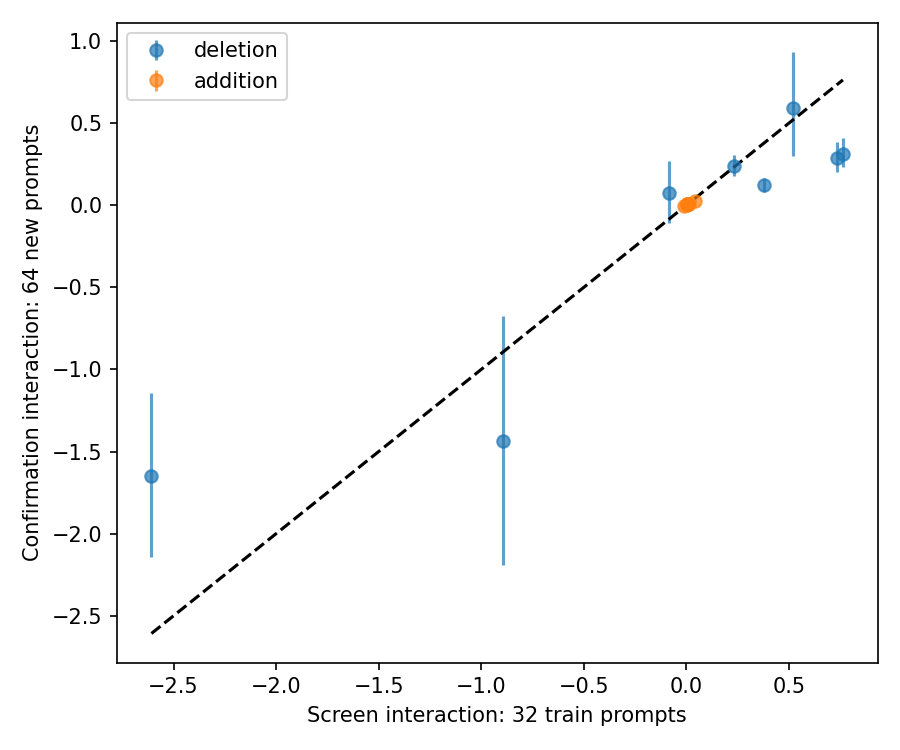

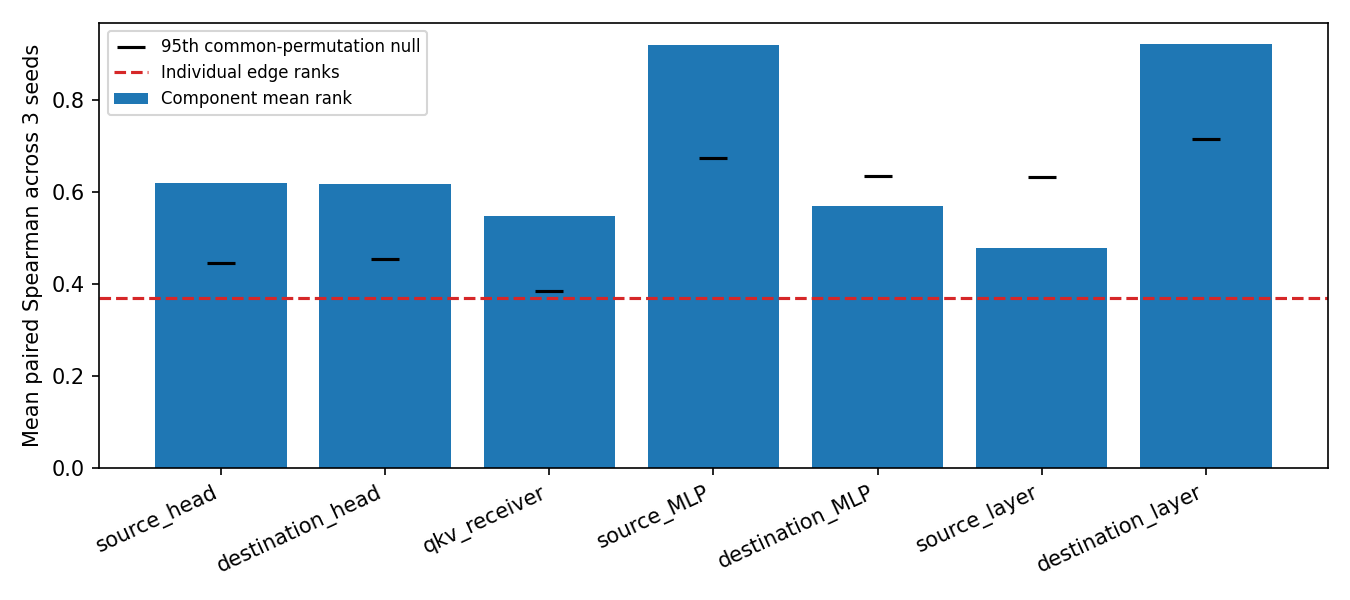

{'recommendation': 'Option B',
 'option_A': False,
 'option_B': True,
 'primary_confirmation_pairs': 16,
 'reproduced_substantial_pairs': 2,
 'reproduced_fraction': 0.125,
 'useful_excluded_additions': 0,
 'component_groupings_passing': ['source_head',
  'destination_head',
  'qkv_receiver',
  'source_MLP',
  'destination_layer'],
 'within_component_vs_matched_control': {'comparisons': 11,
  'mean_ratio': 28.075866130265318,
  'difference': 0.2718339995904402,
  'lo': 0.22327758473428813,
  'hi': 0.32223073911260475,
  'passed': True},
 'model_training_updates': 0,
 'protocol_sha256': '2ed5dd02a7b58377b532e3753abf088034a68c999d17766953bc2c6d60ea1519'}

# Gate 5B: Edge interactions and component structure

Frozen diagnostic decision: **Option B**. No MAttr training, new mask algorithm, ranking refinement, or leaderboard submission occurred.

## Design and intervention semantics

GPT-2 Small, official MIB IOI, all32,491 edges. Saved Gate2 N128 rankings at5000 updates; seed42 interventions, seeds42/43/44 offline stability. Screen uses the first32 exact discovery rows; confirmation uses64 newly selected official validation prompts disjoint by row and clean prompt from prior small Gate2â€“5A development/confirmation manifests and from discovery prompts. Historical Gate1 used full validation, so this is fresh relative to development cohorts, not untouched across all research. Protocol SHA-256 `2ed5dd02a7b58377b532e3753abf088034a68c999d17766953bc2c6d60ea1519`.

Each base circuit is selected by official signed apply_topn and connectivity pruning. Subsequent individual/joint toggles are accepted only if official prune leaves exactly that mask. This fixes circuit context and prevents collateral cleanup from masquerading as interactions. Unsafe paths are recorded in topology_selection_audit.csv. Pruning stays enabled in the evaluator; disconnected additions are excluded. Consequently these diagnostics do not exhaust interactions requiring several new connecting edges.

The official evaluate_graph patcher is used verbatim. Safe caching stores immutable donor-only source matrices; every clean/patched source is recomputed live. Source/model/token/mask/cohort identities guard caches. Correctness compares dependent multi-edge paths against the pinned corrected MAttr live closure without running its trainer, and checks cache equivalence, repeatability and singleton batching. Per-example output is the official correct-minus-incorrect logit difference and official vocabulary top1 accuracy, not a homemade CPR/CMD. CPR/CMD are not computed for this bounded pair experiment.

## Pair selection and screening

48 candidates at each1%/2% nominal cutoff:24 retained and24 excluded, combining high/boundary/disagreement strata. Parent/head diversity and MLP connections are recorded. Up to120 unique i<j pairs per cutoff, stratified by receiver, shared component, cross-component and matched random controls. Shortfalls are reported rather than filling an unregistered sweep. Selection uses only learned train rankings/topology, including saved signed EAP-IG scores. Full all-pairs matrices are never constructed.

| fraction | direction | candidates | valid_pairs | joint_cleanup_rejections | selected_pairs | safe_singles_total | base_edges | requested_edges |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0.0100 | deletion | 24 | 276 | 0 | 49 | 7033 | 317 | 324 |
| 0.0100 | addition | 24 | 276 | 0 | 47 | 7033 | 317 | 324 |
| 0.0200 | deletion | 24 | 276 | 0 | 47 | 10800 | 646 | 649 |
| 0.0200 | addition | 24 | 276 | 0 | 48 | 10800 | 646 | 649 |

| fraction | direction | pairs | mean_abs_interaction | median_abs_interaction | substantial_fraction | additive_sign_disagreements |
| --- | --- | --- | --- | --- | --- | --- |
| 0.0100 | addition | 47 | 0.0009 | 0.0002 | 0.0000 | 0 |
| 0.0100 | deletion | 49 | 0.0843 | 0.0046 | 0.0612 | 0 |
| 0.0200 | addition | 48 | 0.0025 | 0.0003 | 0.0000 | 0 |
| 0.0200 | deletion | 47 | 0.1543 | 0.0335 | 0.0213 | 0 |

Interactions are joint-minus-singleton-sum. A substantial interaction requires absolute mean>=.1 logit margin and relative magnitude>=.2, denominator max(.1,|single_i|+|single_j|). These are exploratory decision thresholds frozen before effects. A large interaction is not necessarily beneficial, and a deletion interaction does not demonstrate a missed addition.

## Held-out confirmation

Top3 absolute interactions plus1 joint-gain extremum per cutoff/direction were selected on train only; matched previously screened random controls were then selected by type/layer signature. Selection IDs and hashes were frozen before loading confirmation prompts. All uncertainty resamples prompts with shared draws across pairs. Tables provide95% and familywise Bonferroni intervals; pair rows are correlated and never treated as independent bootstrap units.

| fraction | direction | pairs | sign_consistency | reproduced_substantial | familywise_CI_nonzero | useful_additions | joint_accuracy_gain |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0.0100 | addition | 4 | 1.0000 | 0 | 3 | 0 | 0.0000 |
| 0.0100 | deletion | 4 | 1.0000 | 1 | 4 | 0 | -0.0078 |
| 0.0200 | addition | 4 | 1.0000 | 0 | 2 | 0 | 0.0000 |
| 0.0200 | deletion | 4 | 0.7500 | 1 | 3 | 0 | 0.0000 |

Primary pairs reproduced with substantial magnitude, consistent sign and nonzero95% CI: **2/16**. Useful held-out additions meeting the frozen margin, singleton and accuracy safeguards: **0**. Full values, sign consistency and familywise intervals are in heldout_consistency.csv; confirmation contains both primary and matched-control rows.

| pair_id | direction | interaction_train | interaction_validation | interaction_lo | interaction_hi | joint_validation | accuracy_joint | sign_consistent | useful_addition |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0.01_deletion_22442_24929 | deletion | 0.3771 | 0.1225 | 0.0812 | 0.1684 | -0.6194 | 0.0000 | True | False |
| 0.01_deletion_18562_21956 | deletion | 0.7635 | 0.3149 | 0.2323 | 0.4074 | -3.9878 | -0.0156 | True | False |
| 0.01_deletion_21956_22442 | deletion | 0.7341 | 0.2904 | 0.2048 | 0.3873 | -0.4942 | 0.0000 | True | False |
| 0.01_deletion_18562_30190 | deletion | 0.2310 | 0.2398 | 0.1756 | 0.3086 | -5.2604 | -0.0156 | True | False |
| 0.01_addition_3496_22242 | addition | 0.0095 | 0.0050 | 0.0027 | 0.0079 | 0.1657 | 0.0000 | True | False |
| 0.01_addition_26876_30108 | addition | 0.0089 | 0.0054 | -0.0021 | 0.0118 | 0.0559 | 0.0000 | True | False |
| 0.01_addition_1004_22242 | addition | 0.0045 | 0.0070 | 0.0034 | 0.0116 | 0.2612 | 0.0000 | True | False |
| 0.01_addition_1004_30972 | addition | 0.0027 | 0.0045 | 0.0024 | 0.0070 | 0.4724 | 0.0000 | True | False |
| 0.02_deletion_24258_24929 | deletion | -2.6082 | -1.6484 | -2.1427 | -1.1450 | -8.5274 | 0.0000 | True | False |
| 0.02_deletion_17334_18562 | deletion | -0.0855 | 0.0719 | -0.1068 | 0.2724 | -9.5430 | 0.0000 | False | False |
| 0.02_deletion_22442_24258 | deletion | 0.5201 | 0.5937 | 0.3018 | 0.9358 | -5.8458 | 0.0000 | True | False |
| 0.02_deletion_4535_18562 | deletion | -0.8919 | -1.4379 | -2.1890 | -0.6755 | -13.1672 | 0.0000 | True | False |
| 0.02_addition_30972_31884 | addition | 0.0418 | 0.0252 | 0.0186 | 0.0318 | 0.4887 | 0.0000 | True | False |
| 0.02_addition_23446_30972 | addition | 0.0117 | 0.0057 | 0.0042 | 0.0074 | 0.5083 | 0.0000 | True | False |
| 0.02_addition_24908_26098 | addition | -0.0113 | -0.0053 | -0.0143 | 0.0038 | 0.0741 | 0.0000 | True | False |
| 0.02_addition_29457_30972 | addition | 0.0029 | 0.0008 | -0.0007 | 0.0022 | 0.5047 | 0.0000 | True | False |

## Component structure and stability

Edges are grouped separately by source head, destination head, Q/K/V receiver, source/destination MLP and source/destination layer. Counts, retained fractions, eligibility-normalized enrichment, score distributions and rank distributions are saved for every group/seed/cutoff. The same edge can participate in different diagnostic groupings; grouping is not a partition across all tables. Edge sets use official connectivity-pruned membership; component ranks use mean percentile importance so size alone cannot dominate.

| grouping | components | edge_mean_spearman | component_mean_spearman | component_gain | common_permutation_null_mean | common_permutation_null_95 | above_null_95 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| source_head | 144 | 0.3689 | 0.6199 | 0.2510 | 0.3401 | 0.4465 | True |
| destination_head | 144 | 0.3689 | 0.6174 | 0.2486 | 0.3305 | 0.4554 | True |
| qkv_receiver | 432 | 0.3689 | 0.5469 | 0.1781 | 0.3188 | 0.3839 | True |
| source_MLP | 12 | 0.3689 | 0.9207 | 0.5519 | 0.3065 | 0.6738 | True |
| destination_MLP | 12 | 0.3689 | 0.5688 | 0.1999 | 0.3097 | 0.6355 | False |
| source_layer | 12 | 0.3689 | 0.4779 | 0.1090 | 0.3166 | 0.6329 | False |
| destination_layer | 12 | 0.3689 | 0.9231 | 0.5542 | 0.3332 | 0.7161 | True |

The200 common edge-label permutations preserve cross-seed edge covariance, component sizes and overlapping group assignments. They test whether averaging correlated edge scores alone explains apparent stability. Top10% component/edge overlaps use comparable selection fractions but distinct units; official edge overlap at.5/1/2/5% is also saved. Three seeds give descriptive variation, not a training-randomness significance claim. Existing EAP-IG correlations are observational references, not new baseline runs.

Within-component primary versus type/layer-matched control comparison: `{"comparisons": 11, "mean_ratio": 28.075866130265318, "difference": 0.2718339995904402, "lo": 0.22327758473428813, "hi": 0.32223073911260475, "passed": true}`. Prompt-resampled confidence bounds apply to the mean difference of absolute mean interactions, with shared draws. Unmatched structural/layer differences and train-selected extremal pairs limit causal interpretations. Control matching quality is explicitly recorded; sparse candidate strata may not permit exact matching.

## Decision and limitations

Option A passes only with at least4 substantial reproducible primary interactions, at least50% primary reproducibility and2 jointly useful excluded additions with positive held-out accuracy gain. Option B passes only if at least2 groupings exceed individual-edge Spearman by.1 and the95th size/covariance-preserving null, plus >=1.5 within-component interaction concentration with a positive bootstrap difference bound. Actual frozen decision: `{"recommendation": "Option B", "option_A": false, "option_B": true, "primary_confirmation_pairs": 16, "reproduced_substantial_pairs": 2, "reproduced_fraction": 0.125, "useful_excluded_additions": 0, "component_groupings_passing": ["source_head", "destination_head", "qkv_receiver", "source_MLP", "destination_layer"], "within_component_vs_matched_control": {"comparisons": 11, "mean_ratio": 28.075866130265318, "difference": 0.2718339995904402, "lo": 0.22327758473428813, "hi": 0.32223073911260475, "passed": true}, "model_training_updates": 0, "protocol_sha256": "2ed5dd02a7b58377b532e3753abf088034a68c999d17766953bc2c6d60ea1519"}`.

These measurements cannot establish that a new masking algorithm would improve MAttr: its existing joint soft-mask objective already encounters interactions. Candidate selection is deliberately local around two small circuits and excludes cleanup-confounded paths. IOI prompts share templates; prompt-bootstrap intervals quantify sampling of this cohort and do not establish template-family generalization. Large margins need not improve behavioral fidelity. Fresh confirmation is small and historical full-validation exposure remains. Neither proposed algorithm is implemented or authorized automatically; the original Gate5 ranking refinement remains deferred.

## Compute and preservation

| stage | success | seconds | forward_batches | example_forwards | backward_calls | optimizer_updates | peak_allocated_mib | peak_reserved_mib | sampled_peak_cpu_rss_mib |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| offline_ranking_stability | True | 4.5262 | 0 | 0 | 0 | 0 | 0.0000 | 0.0000 | 1088.7266 |
| model_loading | True | 15.5636 | 0 | 0 | 0 | 0 | 635.5142 | 690.0000 | 2975.6562 |
| training_cohort_loading | True | 0.9314 | 0 | 0 | 0 | 0 | 635.5142 | 690.0000 | 1189.4922 |
| correctness_checks | True | 7.9163 | 80 | 136 | 0 | 0 | 842.1724 | 922.0000 | 1779.1836 |
| training_screen | True | 163.5473 | 2296 | 9184 | 0 | 0 | 951.2422 | 1474.0000 | 2117.5078 |
| confirmation_cohort_loading | True | 4.0941 | 0 | 0 | 0 | 0 | 675.5415 | 1474.0000 | 2127.7930 |
| heldout_confirmation | True | 74.3669 | 1072 | 4288 | 0 | 0 | 965.3169 | 1690.0000 | 2746.2891 |

Total process wall time: **4.78min**; actual root forward batches **3,448**, example-forwards **13,608**, model backwards/optimizer updates **0/0**. Exact evaluation cache hits **528**, donor cache hits **3338**, unique exact evaluations **373**. Peak CUDA allocation **965.3MiB**. Stage timers synchronize CUDA and use monotonic perf_counter; CPU offline work is separately labeled. CPU donor-cache bytes are recorded, not counted as VRAM. Raw masks, cached outputs and prompt manifests stay local; small per-example effects contain indices and numerical effects only. Completed artifact checks protect every pre-existing tracked file. No model weights, tokens or private data are published.






## Additional artifact audit and conditional effects

All three saved Gate2 rankings vary both discovery subset and training RNG; their stability analysis cannot separate these sources. This diagnostic does not infer a causal benefit of hierarchy or interaction-aware training. Candidate and matched-control strata are limited and train-selected; observed rates are not prevalence estimates for the full graph.

| fraction | direction | control | pairs | mean_abs_interaction | mean_joint_effect | mean_accuracy_effect |
| --- | --- | --- | --- | --- | --- | --- |
| 0.0100 | addition | False | 32 | 0.0011 | 0.1273 | -0.0029 |
| 0.0100 | addition | True | 15 | 0.0006 | 0.1464 | -0.0021 |
| 0.0100 | deletion | False | 34 | 0.1129 | -1.7558 | -0.0184 |
| 0.0100 | deletion | True | 15 | 0.0195 | -1.1865 | -0.0104 |
| 0.0200 | addition | False | 33 | 0.0034 | 0.0365 | 0.0000 |
| 0.0200 | addition | True | 15 | 0.0004 | 0.0146 | 0.0000 |
| 0.0200 | deletion | False | 32 | 0.1655 | -3.2274 | 0.0000 |
| 0.0200 | deletion | True | 15 | 0.1302 | -3.3701 | 0.0000 |

| direction | stratum_i | stratum_j | pairs | mean_abs_interaction | sign_disagreements |
| --- | --- | --- | --- | --- | --- |
| addition | boundary | boundary | 23 | 0.0014 | 0.0000 |
| addition | boundary | disagreement | 29 | 0.0009 | 0.0000 |
| addition | disagreement | boundary | 17 | 0.0010 | 0.0000 |
| addition | disagreement | disagreement | 26 | 0.0034 | 0.0000 |
| deletion | boundary | boundary | 7 | 0.0010 | 0.0000 |
| deletion | boundary | disagreement | 5 | 0.0019 | 0.0000 |
| deletion | boundary | high | 9 | 0.0080 | 0.0000 |
| deletion | disagreement | boundary | 13 | 0.0047 | 0.0000 |
| deletion | disagreement | disagreement | 11 | 0.2043 | 0.0000 |
| deletion | disagreement | high | 14 | 0.1824 | 0.0000 |
| deletion | high | boundary | 11 | 0.0055 | 0.0000 |
| deletion | high | disagreement | 12 | 0.0749 | 0.0000 |
| deletion | high | high | 14 | 0.3907 | 0.0000 |

Within-component retained-edge overlaps are saved in within_component_edge_stability.csv (empty unions are undefined, not perfect stability). Component-only cross-seed prediction and descriptive within-seed variance explained are in component_identity_explanation.csv. These are additional diagnostics, not new selection objectives or modified success criteria.

| grouping | within_source_seed_eta_squared | cross_seed_component_only_R2 | cross_seed_component_prediction_spearman | cross_seed_individual_edge_spearman_same_edges |
| --- | --- | --- | --- | --- |
| destination_MLP | 0.0252 | 0.0082 | 0.0997 | 0.6399 |
| destination_head | 0.0103 | 0.0034 | 0.0597 | 0.3520 |
| destination_layer | 0.0042 | 0.0037 | 0.0527 | 0.3649 |
| qkv_receiver | 0.0288 | 0.0040 | 0.0847 | 0.3520 |
| source_MLP | 0.0410 | 0.0318 | 0.1989 | 0.5705 |
| source_head | 0.0172 | 0.0044 | 0.0740 | 0.3424 |
| source_layer | 0.0009 | -0.0002 | 0.0096 | 0.3667 |

Important control limitation: **0/16 confirmation control matches were exact on all source/destination type and layer fields**. They are the closest available controls in the frozen candidate set. The large within-component/control contrast therefore remains vulnerable to layer/connectivity confounding; it is not a causal component-structure result. No extra controls were added after outcomes.

Component means can rank consistently while explaining little individual-edge variation. Source-head component-only cross-seed R2 averages 0.0044 and source-MLP R2 0.0318 here; a coarse component constraint could discard important edge-specific information. The formal frozen gate favors OptionB as a research hypothesis, not a validated replacement for edge-level masking.

Final diagnostic conclusion: 15/16 primary interaction signs agreed between train and confirmation, but only 2/16 met the full substantial/reproducible criterion and 0 excluded additions passed the usefulness/accuracy rule. Held-out conditional edge-effect sign reversals: 0. Frozen recommendation: Option B. These diagnostics do not demonstrate that a proposed algorithm improves CPR; do not begin either algorithm automatically.


Conditional edge effects `joint - other_single` and their sign changes are in conditional_edge_effects.csv. These expose context-dependent usefulness without interpreting every nonadditive pair as a missed useful circuit. Canonical mappings, exact mask cleanup, cache algebra, selection hashes, disjoint cohorts, forward counters and unchanged historical files were independently audited with zero additional model forwards.


In [7]:
for name in ['additive_vs_joint', 'interaction_distribution', 'interaction_by_category', 'train_vs_heldout', 'edge_vs_component_stability']:
    display(Image(filename=str(OUT / 'figures' / (name + '.png'))))
display(json.loads((OUT / 'research_decision.json').read_text()))
body = (OUT / 'GATE5B_INTERACTION_DIAGNOSTICS_REPORT.md').read_text()
body = re.sub(r'^!\[.*?\]\(.*?\)\s*$', '', body, flags=re.MULTILINE)
display(Markdown(body))
